**Live Deployment Link:** https://YOUR-APP-NAME.streamlit.app/  *(replace with your own live link)*

**GitHub Repo:** https://github.com/YOUR-USERNAME/heart-disease-prediction

# Heart Disease Prediction System
**Course:** AIC354 Machine Learning Fundamentals | **Assignment 2, Task 2** | COMSATS University Islamabad, Lahore Campus

**Name:** YOUR NAME  |  **Reg. No:** YOUR REG NO

## Introduction

**Definition:** A binary classification ML task that predicts whether a patient has heart disease (1) or does not have heart disease (0) from a small number of patient attributes.

**Dataset:** UCI Heart Disease dataset (Cleveland subset, 303 patients): https://archive.ics.uci.edu/dataset/45/heart+disease. Original target `num` is 0 (no disease) to 4 (disease severity). It is converted to binary: 0 = No, 1-4 = Yes.

**Constraint:** only **4 input attributes** are used.

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Source column** | **Possible Values** |
| --- | --- | --- |
| **AgeGroup** | `age` (binned) | Young (< 45), Middle (45-59), Senior (60+) |
| **Sex** | `sex` | Male, Female |
| **ChestPain** | `cp` | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **MaxHeartRate** | `thalach` (binned) | Low (< 120), Medium (120-150), High (> 150) |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **HeartDisease** | Yes, No |

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data
- Step 6: Execute the Training Phase
- Step 7: Execute the Testing Phase
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deploy Your Model as a Public Web App

### Step 1: Import Libraries

In [31]:
"""
Purpose: import the libraries for data handling, label encoding, splitting data,
training a Support Vector Classifier (same model as the Titanic system),
evaluation and plotting.
"""
%pip install prettytable
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Step 2: Load Sample Data
Download `processed.cleveland.data` from the UCI link above (Data Folder) and keep it in the same folder as this notebook. The file has no header row, so the column names are given manually.

In [32]:
"""
Purpose: load the raw UCI Cleveland file into a pandas DataFrame.
Missing values are marked with '?' in this file.
"""
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

raw_data = pd.read_csv("processed.cleveland.data", header=None,
                       names=column_names, na_values="?")

print("\n\nRaw Data (first 10 rows):")
print("=========================\n")
print(raw_data.head(10))
print("\nShape:", raw_data.shape)



Raw Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.0  

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [33]:
print("\n\nAttributes in Raw Data:")
print("=======================\n")
print(raw_data.columns)

print("\n\nNumber of Instances in Raw Data:", raw_data["age"].count())
print("====================================\n")

print("Missing values per attribute:")
print(raw_data.isna().sum())

print("\nOriginal target (num) distribution:")
print(raw_data["num"].value_counts().sort_index())



Attributes in Raw Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')


Number of Instances in Raw Data: 303

Missing values per attribute:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Original target (num) distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
Pre-processing performed:
1. **Keep only 4 input attributes** (`age`, `sex`, `cp`, `thalach`) and the target (`num`), as required by the assignment.
2. **Convert the target to binary:** `num = 0` -> No, `num` 1 to 4 -> Yes.
3. **Convert numeric codes to readable text categories** (same style as the Titanic data: First/Second/Third, Male/Female, ...).

In [34]:
# 1. Keep only 4 input attributes + target
data = raw_data[["age", "sex", "cp", "thalach", "num"]].copy()

# (these 5 columns have no missing values; dropna is a safety step)
data = data.dropna().reset_index(drop=True)

# 2. Binary target
data["HeartDisease"] = np.where(data["num"] == 0, "No", "Yes")

# 3. Readable categories
data["Sex"] = data["sex"].map({1: "Male", 0: "Female"})
data["ChestPain"] = data["cp"].map({1: "Typical Angina", 2: "Atypical Angina",
                                    3: "Non-Anginal Pain", 4: "Asymptomatic"})
print(data[["age", "Sex", "ChestPain", "thalach", "HeartDisease"]].head(10))

    age     Sex         ChestPain  thalach HeartDisease
0  63.0    Male    Typical Angina    150.0           No
1  67.0    Male      Asymptomatic    108.0          Yes
2  67.0    Male      Asymptomatic    129.0          Yes
3  37.0    Male  Non-Anginal Pain    187.0           No
4  41.0  Female   Atypical Angina    172.0           No
5  56.0    Male   Atypical Angina    178.0           No
6  62.0  Female      Asymptomatic    160.0          Yes
7  57.0  Female      Asymptomatic    163.0           No
8  63.0    Male      Asymptomatic    147.0          Yes
9  53.0    Male      Asymptomatic    155.0          Yes


#### Step 4: Feature Extraction
`age` and `thalach` (maximum heart rate) are numeric. To follow the same categorical + Label Encoding flow as the Titanic system, they are converted into groups (feature extraction by binning).

In [35]:
data["AgeGroup"] = pd.cut(data["age"], bins=[0, 44, 59, 200],
                          labels=["Young", "Middle", "Senior"]).astype(str)
data["MaxHeartRate"] = pd.cut(data["thalach"], bins=[0, 119, 150, 300],
                              labels=["Low", "Medium", "High"]).astype(str)

sample_data = data[["AgeGroup", "Sex", "ChestPain", "MaxHeartRate", "HeartDisease"]]
sample_data.to_csv("sample-data.csv", index=False, header=True)

print("\n\nSample Data (ready for encoding):")
print("=================================\n")
print(sample_data.head(10))
print("\nSaved: sample-data.csv  | Instances:", len(sample_data))
print("\nClass balance:")
print(sample_data["HeartDisease"].value_counts())



Sample Data (ready for encoding):

  AgeGroup     Sex         ChestPain MaxHeartRate HeartDisease
0   Senior    Male    Typical Angina       Medium           No
1   Senior    Male      Asymptomatic          Low          Yes
2   Senior    Male      Asymptomatic       Medium          Yes
3    Young    Male  Non-Anginal Pain         High           No
4    Young  Female   Atypical Angina         High           No
5   Middle    Male   Atypical Angina         High           No
6   Senior  Female      Asymptomatic         High          Yes
7   Middle  Female      Asymptomatic         High           No
8   Senior    Male      Asymptomatic       Medium          Yes
9   Middle    Male      Asymptomatic         High          Yes

Saved: sample-data.csv  | Instances: 303

Class balance:
HeartDisease
No     164
Yes    139
Name: count, dtype: int64


### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [36]:
agegroup = pd.DataFrame({"AgeGroup": ["Young", "Middle", "Senior"]})
sex = pd.DataFrame({"Sex": ["Male", "Female"]})
chestpain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
maxheartrate = pd.DataFrame({"MaxHeartRate": ["Low", "Medium", "High"]})
heartdisease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

agegroup_label_encoder = LabelEncoder()
sex_label_encoder = LabelEncoder()
chestpain_label_encoder = LabelEncoder()
maxheartrate_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()

agegroup_label_encoder.fit(np.ravel(agegroup))
sex_label_encoder.fit(np.ravel(sex))
chestpain_label_encoder.fit(np.ravel(chestpain))
maxheartrate_label_encoder.fit(np.ravel(maxheartrate))
heartdisease_label_encoder.fit(np.ravel(heartdisease))

print("Label encoder classes (code = position in the list):")
for name, enc in [("AgeGroup", agegroup_label_encoder), ("Sex", sex_label_encoder),
                  ("ChestPain", chestpain_label_encoder), ("MaxHeartRate", maxheartrate_label_encoder),
                  ("HeartDisease", heartdisease_label_encoder)]:
    print(f"  {name}: {list(enc.classes_)}")

Label encoder classes (code = position in the list):
  AgeGroup: ['Middle', 'Senior', 'Young']
  Sex: ['Female', 'Male']
  ChestPain: ['Asymptomatic', 'Atypical Angina', 'Non-Anginal Pain', 'Typical Angina']
  MaxHeartRate: ['High', 'Low', 'Medium']
  HeartDisease: ['No', 'Yes']


#### Step 5.2: Label Encode the Output

In [37]:
sample_data_encoded_output = sample_data.copy()

print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
sample_data = sample_data.copy()
sample_data["encoded_heartdisease"] = heartdisease_label_encoder.transform(sample_data["HeartDisease"])
print(sample_data[["HeartDisease", "encoded_heartdisease"]].head(10))

sample_data_encoded_output["HeartDisease"] = sample_data["encoded_heartdisease"]
sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_heartdisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [38]:
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded["AgeGroup"] = agegroup_label_encoder.transform(sample_data_encoded_output["AgeGroup"])
sample_data_encoded["Sex"] = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded["ChestPain"] = chestpain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded["MaxHeartRate"] = maxheartrate_label_encoder.transform(sample_data_encoded_output["MaxHeartRate"])

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded.head(10))
sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)



Sample Data after Label Encoding:

   AgeGroup  Sex  ChestPain  MaxHeartRate  HeartDisease
0         1    1          3             2             0
1         1    1          0             1             1
2         1    1          0             2             1
3         2    1          2             0             0
4         2    0          1             0             0
5         0    1          1             0             0
6         1    0          0             0             1
7         0    0          0             0             0
8         1    1          0             2             1
9         0    1          0             0             1


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [39]:
# 80% training / 20% testing. Rows are shuffled (random_state=0 keeps it reproducible)
# and stratified so both splits keep the same Yes/No proportion.
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded, test_size=0.2, random_state=0, shuffle=True,
    stratify=sample_data_encoded["HeartDisease"])

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)
print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [40]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]
print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### Step 6.3: Train the Support Vector Classifier

In [41]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")
svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [42]:
pickle.dump(svc_model, open("heart_svc_trained_model.pkl", "wb"))
print("Saved: heart_svc_trained_model.pkl")

Saved: heart_svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [43]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]
print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [44]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))
print("Model loaded from heart_svc_trained_model.pkl")

Model loaded from heart_svc_trained_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [45]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by heart_svc_trained_model:")
print("================================================\n")
print(model_predictions.head(15))



Predictions Returned by heart_svc_trained_model:

     AgeGroup  Sex  ChestPain  MaxHeartRate  HeartDisease  Predictions
125         0    0          1             0             0            0
83          1    1          2             2             1            0
53          2    1          1             0             0            0
45          0    1          2             0             1            0
248         0    1          0             0             1            0
211         2    1          3             0             1            0
36          2    1          0             2             1            1
106         0    1          0             0             1            0
120         0    1          0             2             1            1
31          1    1          0             0             1            1
156         0    1          0             0             1            0
157         0    1          0             0             1            0
148         0    1       

#### Step 7.4: Calculate the Accuracy Score

In [46]:
model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])
print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.75


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                   precision    recall  f1-score   support

   No Disease (0)       0.70      0.94      0.81        33
Heart Disease (1)       0.88      0.54      0.67        28

         accuracy                           0.75        61
        macro avg       0.79      0.74      0.74        61
     weighted avg       0.79      0.75      0.74        61



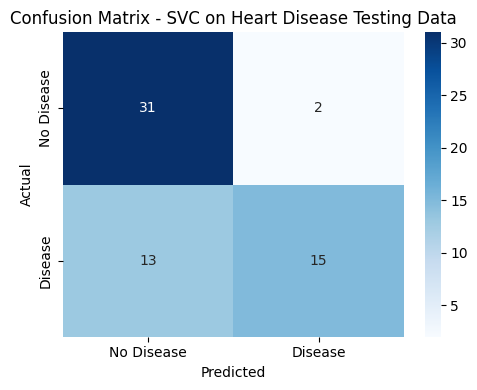

In [47]:
# Note: encoder order is ['No', 'Yes'] -> No = 0, Yes = 1
print("\nClassification Report:")
print("=======================\n")
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"],
                            target_names=["No Disease (0)", "Heart Disease (1)"]))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout(); plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [48]:
"""
Demo patient is pre-filled so the notebook runs top-to-bottom. For interactive input replace with:
    agegroup_input = input("AgeGroup (Young, Middle, Senior): ").strip()
    sex_input = input("Sex (Male, Female): ").strip()
    chestpain_input = input("ChestPain (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
    maxheartrate_input = input("MaxHeartRate (Low, Medium, High): ").strip()
"""
agegroup_input = "Senior"
sex_input = "Male"
chestpain_input = "Asymptomatic"
maxheartrate_input = "Low"
print(f"AgeGroup: {agegroup_input}, Sex: {sex_input}, ChestPain: {chestpain_input}, MaxHeartRate: {maxheartrate_input}")

AgeGroup: Senior, Sex: Male, ChestPain: Asymptomatic, MaxHeartRate: Low


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [49]:
user_input = pd.DataFrame({
    "AgeGroup": [agegroup_input], "Sex": [sex_input],
    "ChestPain": [chestpain_input], "MaxHeartRate": [maxheartrate_input]})
print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

  AgeGroup   Sex     ChestPain MaxHeartRate
0   Senior  Male  Asymptomatic          Low


#### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [50]:
unseen_data_features = user_input.copy()
unseen_data_features["AgeGroup"] = agegroup_label_encoder.transform(user_input["AgeGroup"])
unseen_data_features["Sex"] = sex_label_encoder.transform(user_input["Sex"])
unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["MaxHeartRate"] = maxheartrate_label_encoder.transform(user_input["MaxHeartRate"])
print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   AgeGroup  Sex  ChestPain  MaxHeartRate
0         1    1          0             1


#### Step 8.4: Load the Saved Model

In [51]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))

#### Step 8.5: Model Prediction

##### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [52]:
predicted = model.predict(unseen_data_features)
prediction = "HEART DISEASE LIKELY" if predicted[0] == 1 else "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [53]:
example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Doctor)", "Student Tester", "Student Tester"],
    "Case": [
        "Senior, Male, Asymptomatic chest pain, Low max heart rate -> predicted HEART DISEASE LIKELY",
        "Young, Female, Atypical Angina, High max heart rate -> predicted NO HEART DISEASE",
        "Middle, Male, Typical Angina, Medium max heart rate -> borderline result",
    ],
    "Feedback": [
        "Consistent with clinical risk factors (older age, male, asymptomatic pain, low max heart rate).",
        "Looks reasonable and matches common sense.",
        "Only 4 inputs are used, so borderline cases are uncertain. More attributes would help.",
    ],
})
print(example_feedback.to_string(index=False))

              Reviewer                                                                                        Case                                                                                        Feedback
Domain Expert (Doctor) Senior, Male, Asymptomatic chest pain, Low max heart rate -> predicted HEART DISEASE LIKELY Consistent with clinical risk factors (older age, male, asymptomatic pain, low max heart rate).
        Student Tester           Young, Female, Atypical Angina, High max heart rate -> predicted NO HEART DISEASE                                                      Looks reasonable and matches common sense.
        Student Tester                    Middle, Male, Typical Angina, Medium max heart rate -> borderline result          Only 4 inputs are used, so borderline cases are uncertain. More attributes would help.


#### Step 9.2: Make a List of Potential Improvements

In [54]:
improvements = [
    "Use more attributes (cholesterol, resting blood pressure, exercise-induced angina, oldpeak, ca, thal) beyond the 4 allowed here",
    "Use the numeric values of age and max heart rate directly (with scaling) instead of grouping them",
    "Use all 4 UCI sub-datasets (Cleveland, Hungary, Switzerland, VA) for more patients",
    "Use cross-validation and compare more models (Logistic Regression, Random Forest, Decision Tree)",
    "This system is a learning project only and must not be used for real medical decisions",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more attributes (cholesterol, resting blood pressure, exercise-induced angina, oldpeak, ca, thal) beyond the 4 allowed here
2. Use the numeric values of age and max heart rate directly (with scaling) instead of grouping them
3. Use all 4 UCI sub-datasets (Cleveland, Hungary, Switzerland, VA) for more patients
4. Use cross-validation and compare more models (Logistic Regression, Random Forest, Decision Tree)
5. This system is a learning project only and must not be used for real medical decisions


#### Step 9.3: Improve the Model Based on Feedback

In [55]:
print("Next version: add more attributes, use scaled numeric features, then re-run Steps 6-7 and replace heart_svc_trained_model.pkl only if accuracy improves.")

Next version: add more attributes, use scaled numeric features, then re-run Steps 6-7 and replace heart_svc_trained_model.pkl only if accuracy improves.


## Step 10: Deploy Your Model as a Public Web App

The trained model is deployed with **Streamlit Community Cloud** (same method as the Titanic demo).

1. Create a public GitHub repository (e.g. `heart-disease-prediction`).
2. Upload `app.py`, `requirements.txt`, `runtime.txt` and `heart_svc_trained_model.pkl` to the repo.
3. Go to https://share.streamlit.io, sign in with GitHub, click **Create app** -> **Deploy a public app from GitHub**.
4. Repository = your repo, Branch = `main`, Main file path = `app.py`, then click **Deploy**.
5. Copy the public `https://....streamlit.app` link and paste it at the **very top of this notebook**.

**Troubleshooting:** if you get a `ModuleNotFoundError`, set the Python version to 3.11 or 3.12 in the app's **Settings -> General**.

## Conclusion
A Heart Disease Prediction System was built with the same end-to-end steps as the Titanic system (Data Loading, Pre-processing, Feature Extraction, Label Encoding, Training, Testing, Application, Feedback, Deployment) using only 4 input attributes: age group, sex, chest pain type and maximum heart rate. A Support Vector Classifier was trained and evaluated on held-out data, saved as a `.pkl` file and deployed as a public Streamlit web app. The results are for learning purposes only.